In [1]:
import pandas as pd
import numpy as np
import sklearn
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
File = '/Users/hayk/Desktop/Магистратура ВШЭ/Годовой проект/hu_intraday_vwap_15min_2023_2025 (4).csv'
df = pd.read_csv(File)

In [3]:
df.head()

,timestamp,QH WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
0,2022-12-31 23:00:00+00:00,22.89,3978.2,125.6,0.0,1900.0,5.77,-983.2
1,2022-12-31 23:15:00+00:00,6.54,3994.7,125.1,0.0,1900.0,5.55,-983.2
2,2022-12-31 23:30:00+00:00,4.44,3988.3,126.8,0.0,1900.0,5.36,-983.2
3,2022-12-31 23:45:00+00:00,1.13,3956.0,126.7,0.0,1900.0,5.24,-983.2
4,2023-01-01 00:00:00+00:00,5.30,3936.8,127.4,0.0,1900.0,5.18,-900.0


In [4]:
print(df.shape)
print(f"Всего столбцов: \n{df.count()}")

(105216, 8)
Всего столбцов: 
timestamp                    105216
QH WAP                       105122
demand_forecast_mwh          105216
wind_forecast_mwh            105216
solar_forecast_mwh           105216
nuclear_forecast_mwh         105216
temperature_forecast_c       105216
net_exchange_forecast_mwh    105216
dtype: int64


Сразу видно, что в QH WAP есть пропуски. Их 94 штуки 👆

In [5]:
df.describe()

,QH WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
count,105122.000000,105216.000000,105216.000000,105216.000000,105216.000000,105216.000000,105216.000000
mean,107.527928,4892.300391,67.763118,614.153365,1731.612720,12.529461,-1130.725236
std,82.040454,827.044427,62.953986,905.099074,236.179614,9.209502,1227.760098
min,-561.850000,2332.800000,0.400000,0.000000,956.000000,-7.350000,-5365.300000
25%,69.430000,4262.800000,17.500000,0.000000,1428.000000,4.860000,-1988.325000
50%,99.440000,4827.600000,48.100000,16.150000,1900.000000,12.130000,-1300.000000
75%,135.340000,5453.200000,99.100000,1046.500000,1900.000000,19.750000,-436.250000
max,6326.670000,7376.400000,300.400000,4207.600000,2039.000000,36.010000,3819.900000


In [6]:
X = df.drop(columns='QH WAP')
y = df['QH WAP']

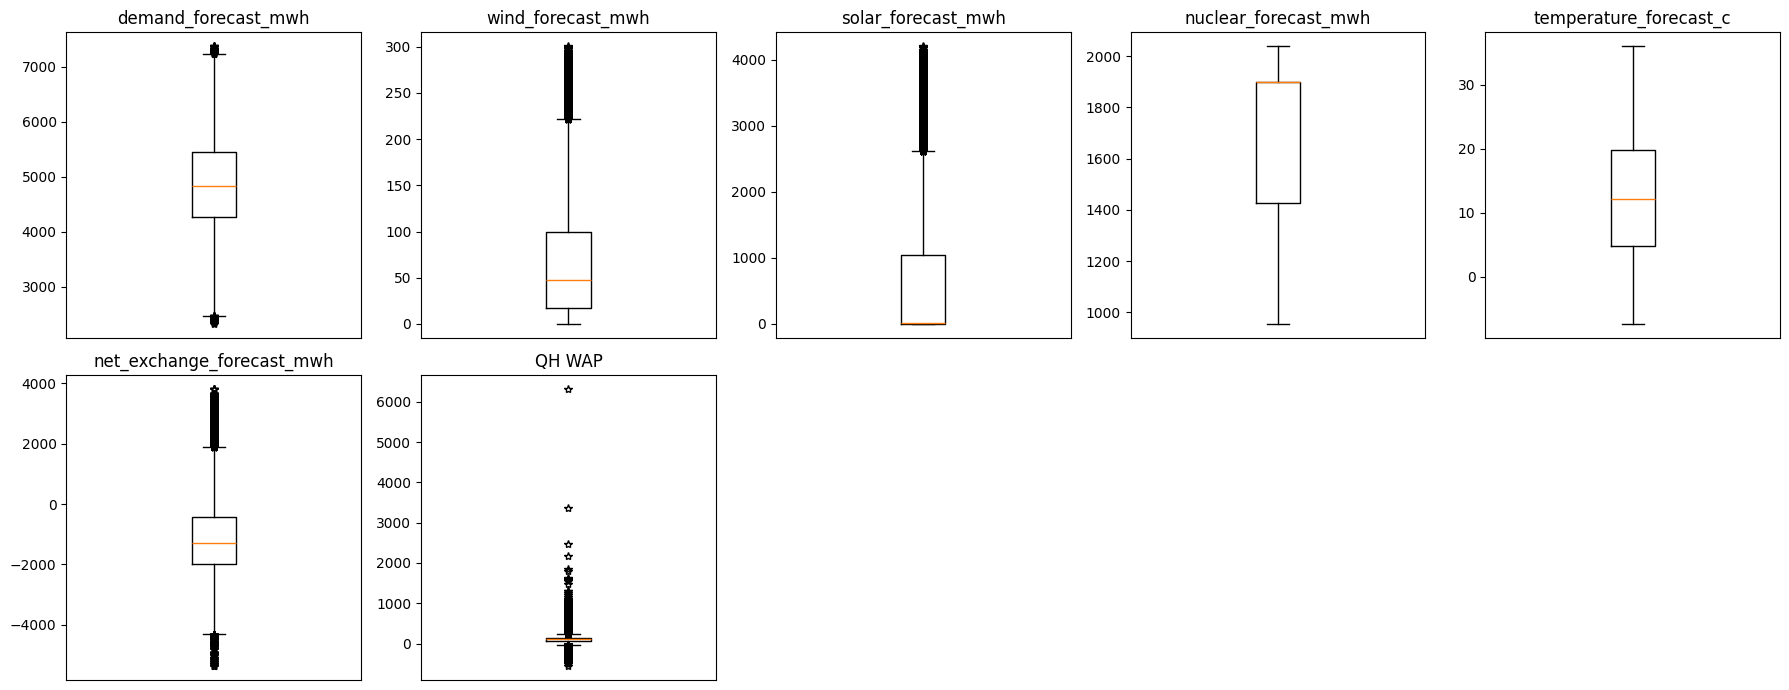

In [7]:
data = pd.concat([X, y], axis=1)
num_cols = data.select_dtypes(include="number").columns

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, num_cols):
    values = data[col].dropna().to_numpy(dtype=float)
    ax.boxplot(values, sym="*")
    ax.set_title(col)
    ax.set_xticks([])

for ax in axes.flat[len(num_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

В общем и целом выбросов кромое  QH WAP нету. В QH WAP нужно обрезать данные, а у остальных оставить как есть. Можно еще обрезать, конечно, у solar_forecast_mwh, тк данные выходят далека за усики. Кстати, исходя из графика solar_forecast_mwh, можно сказать, что min = 0 и медиана 0, что логично(значит данные распределены в основном у цифры 0 и ниже быть не может). Можно так же сказать, что у nuclear_forecst_mwh медиана находится очень, высоко, что говорит нам о том, что в основном цифры будут большие. Кстати QH WAP, когда ниже 0 это значит, что компания уходит в минус. 

In [8]:
# укоротим диапазон значений у QH WAP
plausible = {'QH WAP': (-1000, 1300)}

df_clean = df.copy()

for col, (low, high) in plausible.items():
    in_range = (df["QH WAP"] >= -1000) & (df["QH WAP"] <= 1300)
    df_clean = df[in_range]

In [9]:
# Проверим количество переменных до удаления и после(после удаления должно быть меньша на 94)
print(f"До {df.shape}")
print(f"После {df_clean.shape}")

До (105216, 8)
После (105109, 8)


Выведем ящик с усами теперь получившегося диапазона:

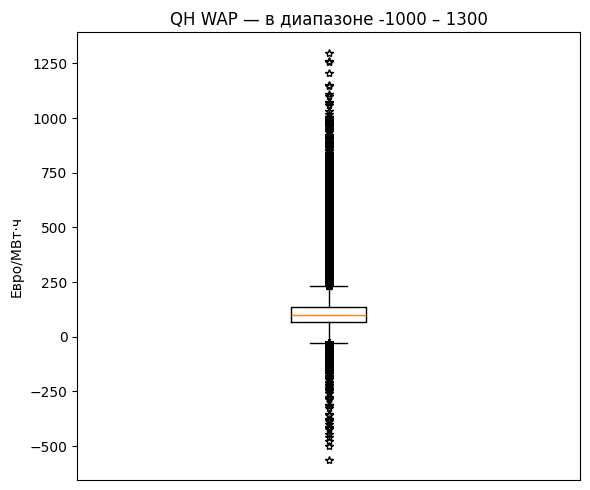

In [10]:
low, high = -1000, 1300

mask = df["QH WAP"].between(low, high) | df["QH WAP"].isna()
df_clean = df[mask]

plt.figure(figsize=(6, 5))
plt.boxplot(df_clean["QH WAP"].dropna().to_numpy(dtype=float), sym="*")
plt.title(f"QH WAP — в диапазоне {low} – {high}")
plt.ylabel("Евро/МВт·ч")
plt.xticks([])
plt.tight_layout()
plt.show()

## Сделаем график распределения данных и посмотрим, что получается

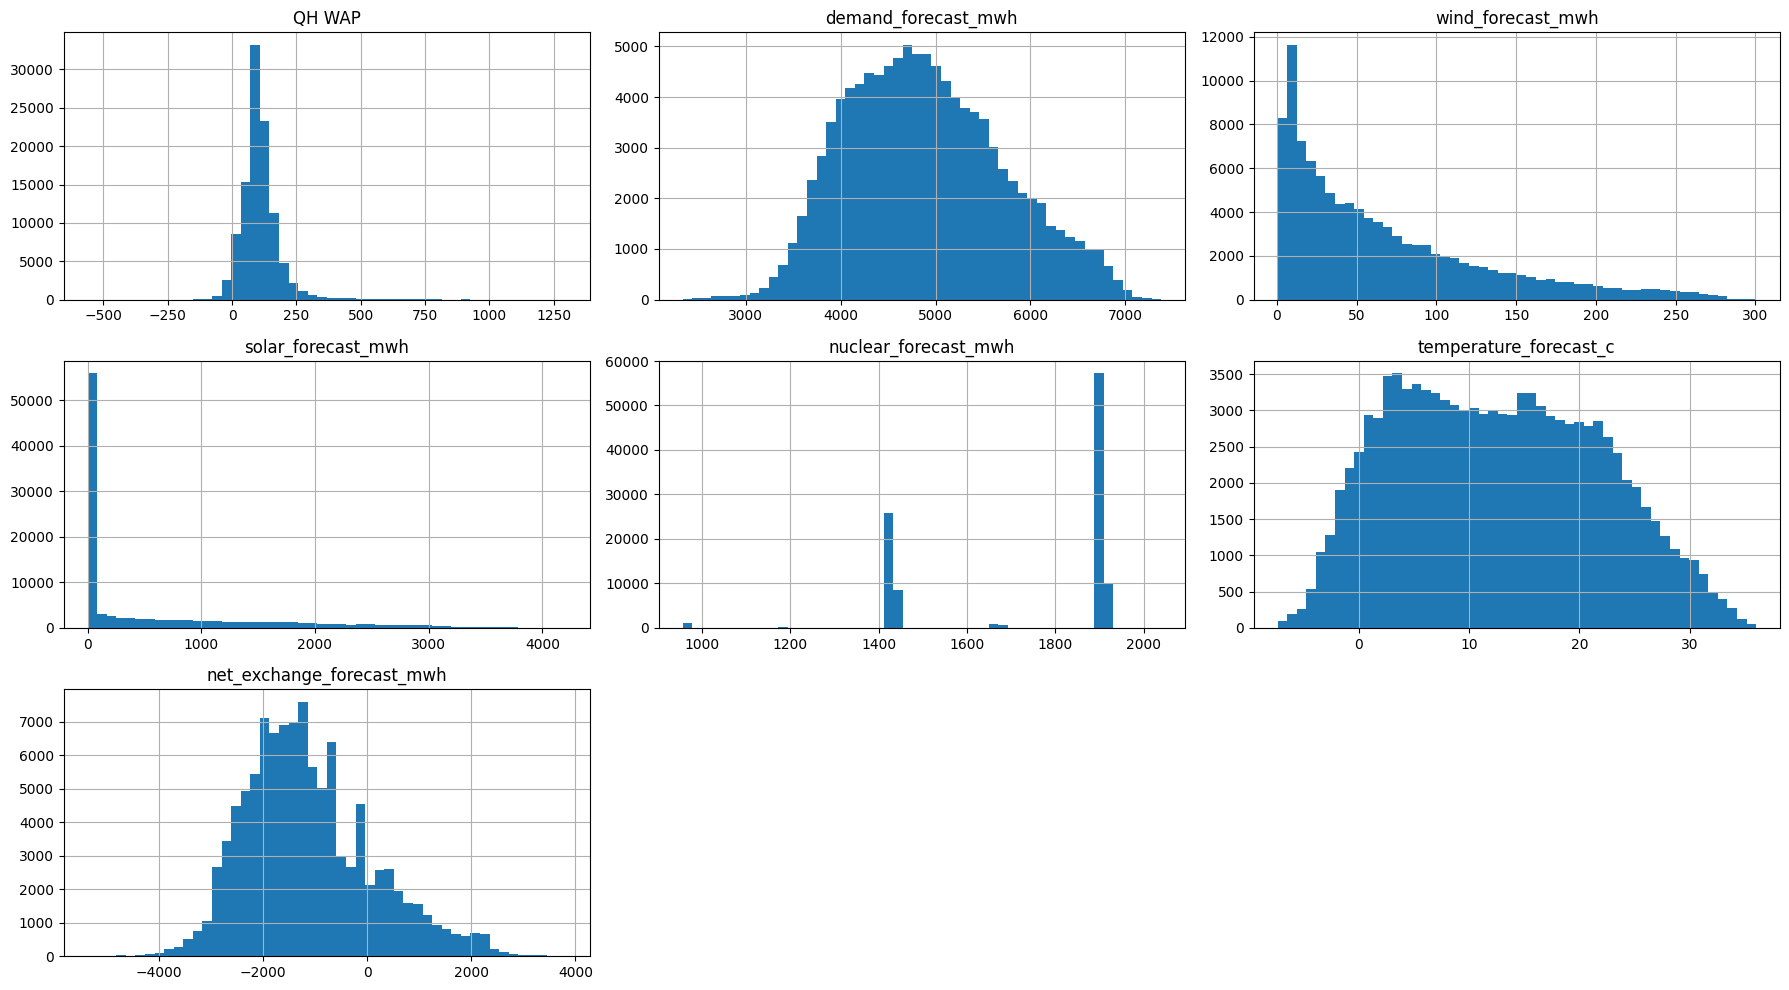

In [11]:
df_clean.hist(figsize=(18, 10), bins=50)
plt.tight_layout()
plt.show()

У всех, кроме QH WAP, solar_forecast_mwh и nuclear_forecast_mwh данные распределены более-менее равномерно по диапахону, а вот у этих выделяется контрастность значений рядом с одним числом. У solar_forecast_mwh это связано с солнечной погодой и ночью. В АЭС работают в определенном темпе(ярко выражены 2 значения). У QH WAP данные распределены плотно в окрестности 107, что говорит о том, что сильных скачков и падений в цене почти не бывают

## Исправляем пропуски

In [12]:
solar_0 = df[df['solar_forecast_mwh'] == 0]
print(f"Количество столбцов, где solar_forecast_mwh = 0: {solar_0['solar_forecast_mwh'].count()} ")

print()
print(f"Пропуски: \n{df_clean.isna().sum()}")
print(df_clean.count())

Количество столбцов, где solar_forecast_mwh = 0: 50098 

Пропуски: 
timestamp                     0
QH WAP                       94
demand_forecast_mwh           0
wind_forecast_mwh             0
solar_forecast_mwh            0
nuclear_forecast_mwh          0
temperature_forecast_c        0
net_exchange_forecast_mwh     0
dtype: int64
timestamp                    105203
QH WAP                       105109
demand_forecast_mwh          105203
wind_forecast_mwh            105203
solar_forecast_mwh           105203
nuclear_forecast_mwh         105203
temperature_forecast_c       105203
net_exchange_forecast_mwh    105203
dtype: int64


## Все данные ненулевые кроме QH WAP 👆
В QH WAP 94 пропуска

In [13]:
df_clean = df_clean[df_clean['QH WAP'].notna()]

In [14]:
df_clean.count()

timestamp                    105109
QH WAP                       105109
demand_forecast_mwh          105109
wind_forecast_mwh            105109
solar_forecast_mwh           105109
nuclear_forecast_mwh         105109
temperature_forecast_c       105109
net_exchange_forecast_mwh    105109
dtype: int64

Теперь все данные без пропусков

## Проверим дубли 

In [15]:
print(f"Дубли времени: {df_clean['timestamp'].duplicated().sum()}")

print(f"Дубли целой строки: {df_clean.duplicated().sum()}")

cols = df_clean.columns.drop("timestamp")
print("Дублей без учёта времени:", df_clean.duplicated(subset=cols).sum())

Дубли времени: 0
Дубли целой строки: 0
Дублей без учёта времени: 0


## Корреляция пирсона

Text(0.5, 1.0, 'Пирсон')

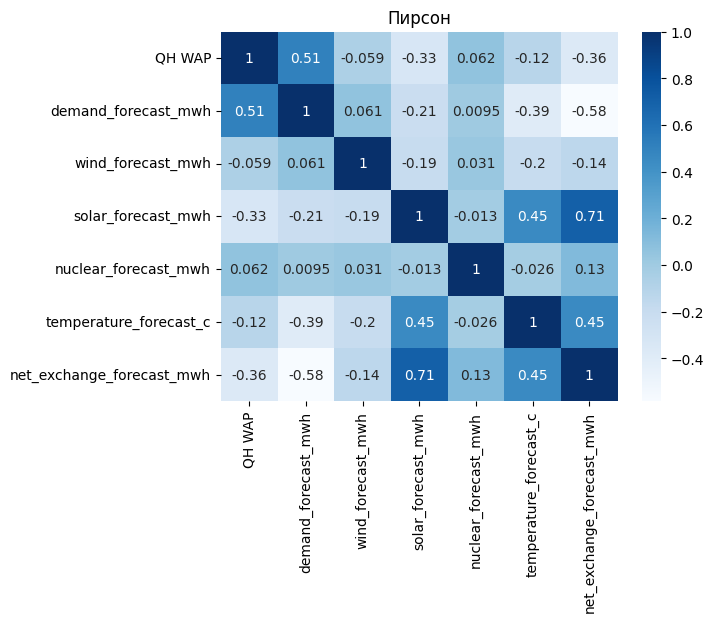

In [16]:
sns.heatmap(df_clean.corr(numeric_only= True), annot=True, cmap = "Blues")
plt.title('Пирсон')

По тепловой карте можно сделать вывод о том, что: 
- рост таргета сильно зависит от потребления электроэнергии(1 к 0.51)
- меньше всего таргет зависит от работы ветровых станций и выроботки АЭС
- солнечные батареи и экспорт оказывают самое большое отрицательное влияние на таргент(-0.36 и -0.33 соответственно)
- солнечные батареи и экспорт тесно друг с другом связаны(0.71). Чем больше солнечной энергии - тем больше экспорта 

## Корреляция Спермана

Text(0.5, 1.0, 'Сперман')

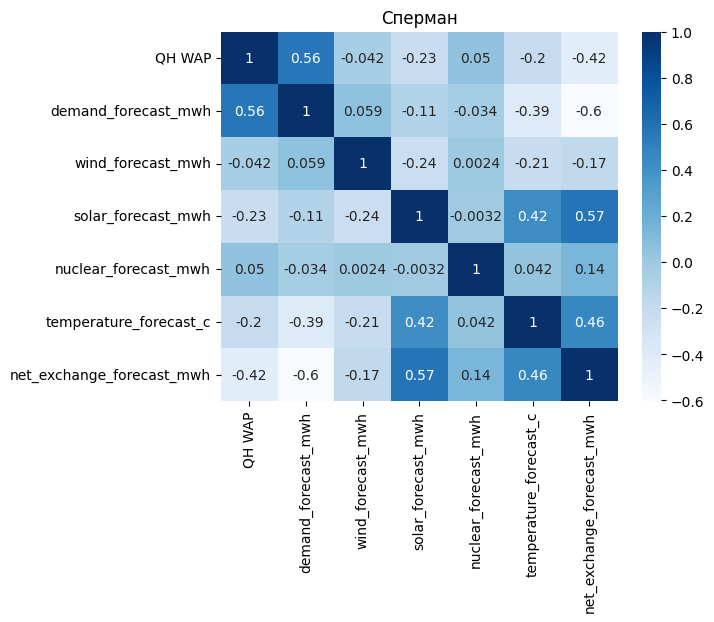

In [17]:
sns.heatmap(df_clean.corr(numeric_only= True, method='spearman'), annot=True, cmap = "Blues")
plt.title('Сперман')

Корреляция по Сперману почти совпала с корреляцией по Пирсону. Единственное - солнечные батареи и экспорт не так тесно связаны друг с другом связаны(с 0.71 на 0.57)

## Корреляция Кендал

Text(0.5, 1.0, 'Кендал')

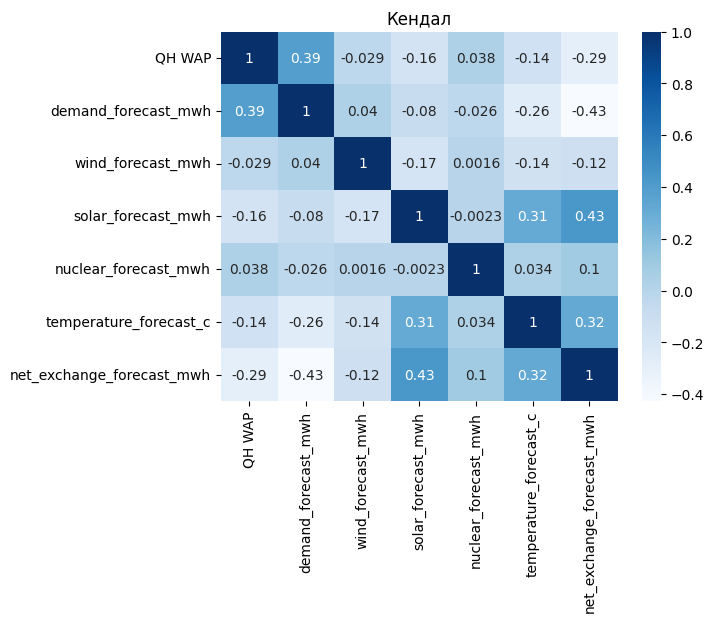

In [18]:
sns.heatmap(df_clean.corr(numeric_only= True, method='kendall'), annot=True, cmap = "Blues")
plt.title('Кендал')

У Кендал зависимости вырвжены в меньших коэффициентах чем у Пирсона и Спермана, но все те же связанные друг с другом зависимости остались в топе(потребление, солнечные батареи, экспорт)

## Графики временного ряда

График по дням со средним за день:

In [19]:
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"], utc=True)
df_clean["timestamp"] = df_clean["timestamp"].dt.tz_convert("Europe/Budapest")

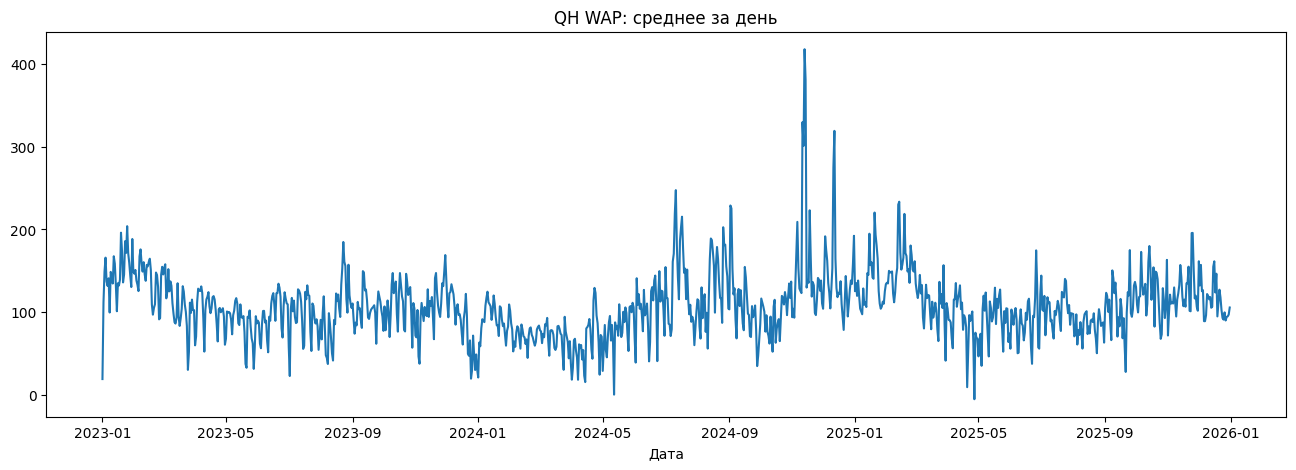

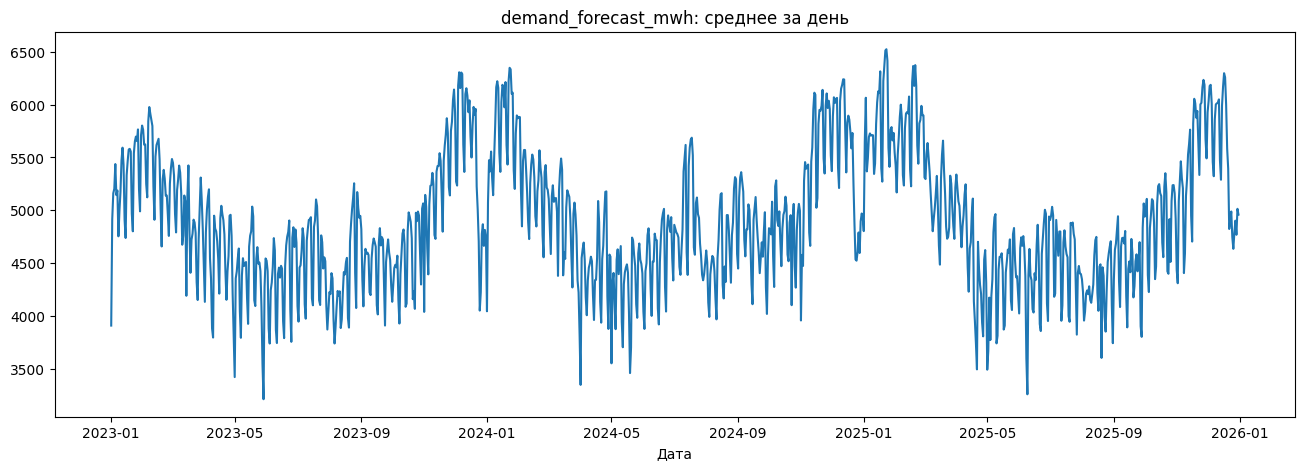

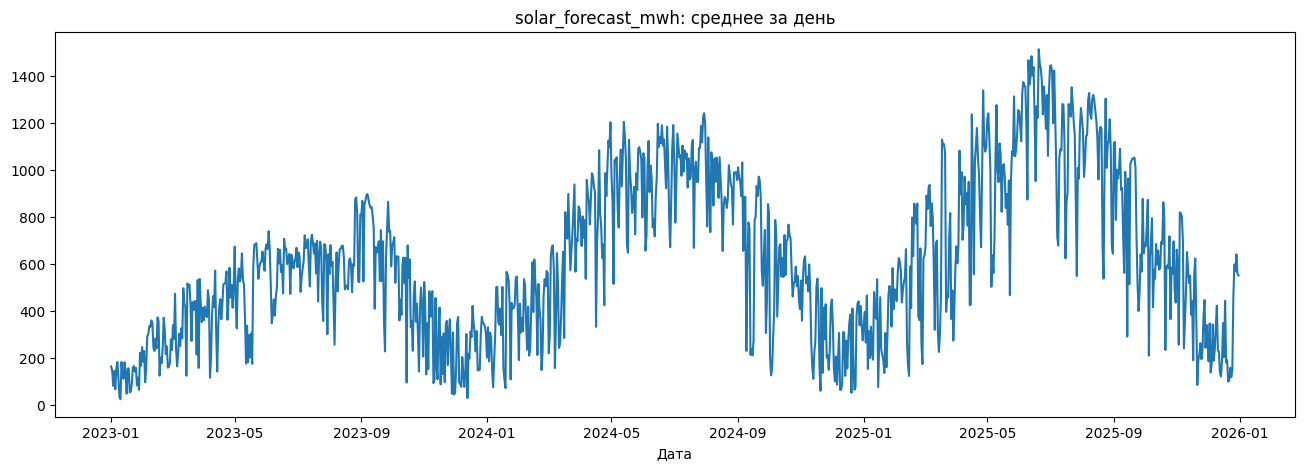

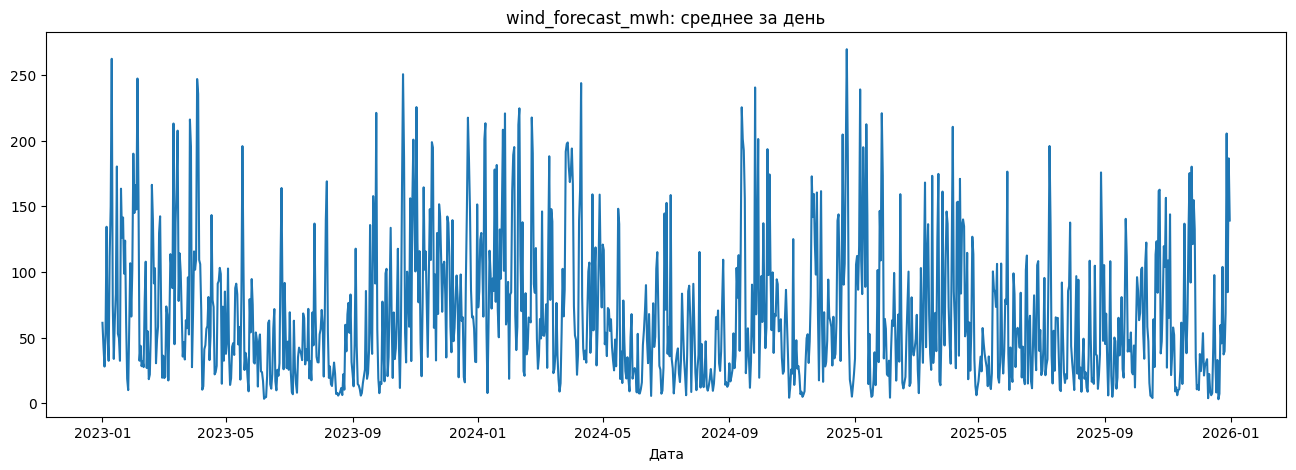

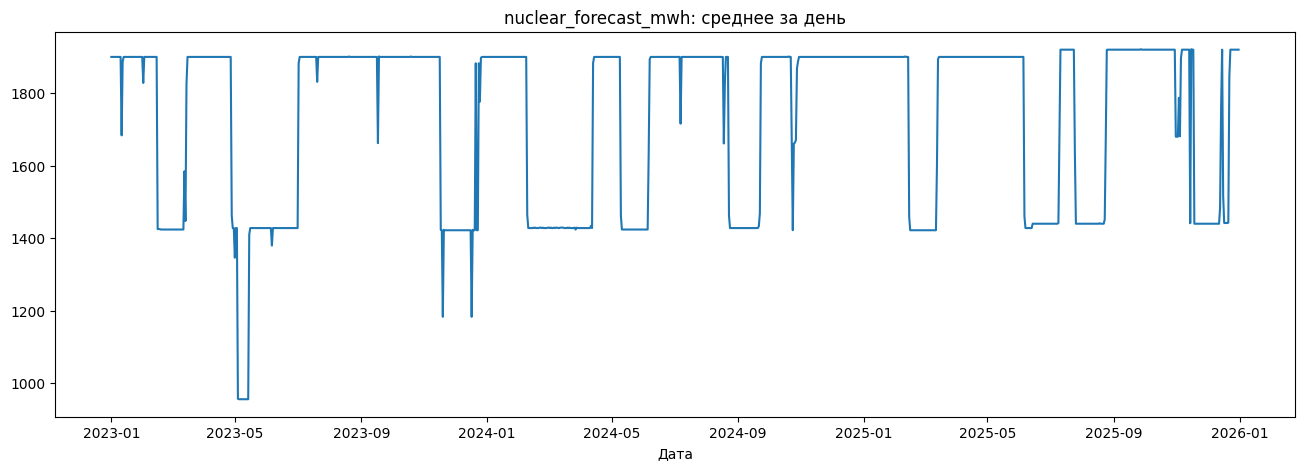

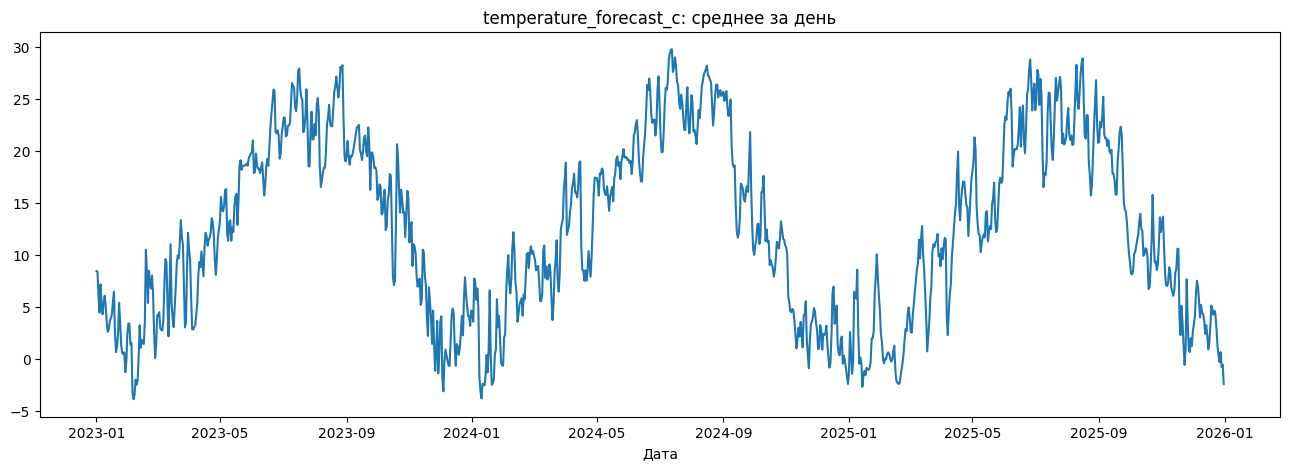

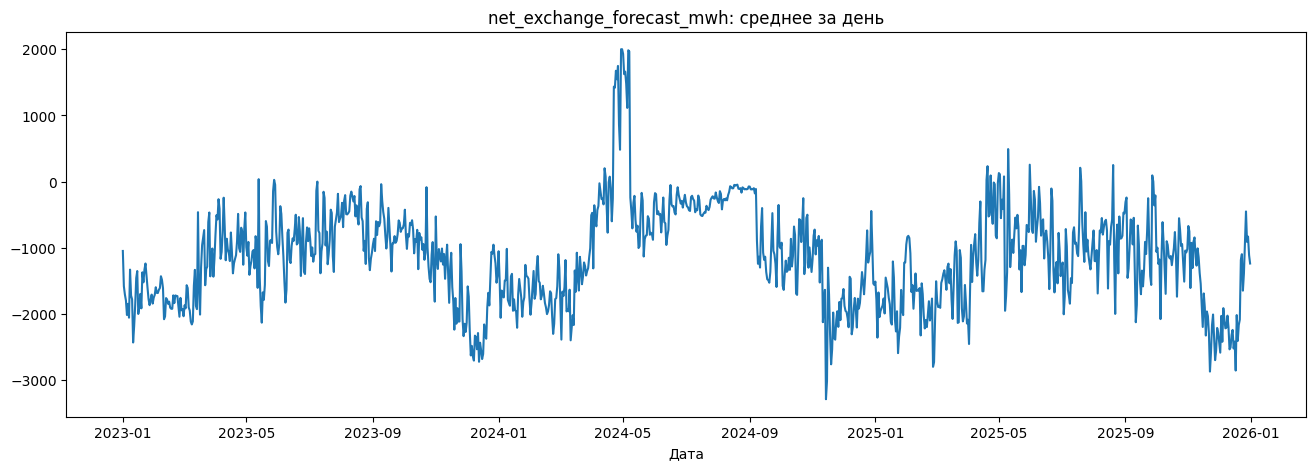

In [20]:
cols = ["QH WAP", "demand_forecast_mwh", "solar_forecast_mwh", "wind_forecast_mwh",
        "nuclear_forecast_mwh", "temperature_forecast_c", "net_exchange_forecast_mwh"]

for col in cols:
    daily = df_clean.set_index("timestamp")[col].resample("D").mean()

    plt.figure(figsize=(16, 5))
    plt.plot(daily.index, daily.values)
    plt.title(f"{col}: среднее за день")
    plt.xlabel("Дата")
    plt.show()

Все графики выглядят нормально. Единственное, значение максимума у QH WAP резко поднимается и падает, надо изучить. Посмотрим окрестность этого максимально значения:

In [21]:
max_qh = df_clean['QH WAP'].max()
df_clean[df_clean['QH WAP'] == max_qh]


max_time = df_clean.loc[df_clean["QH WAP"].idxmax(), "timestamp"]
window = df_clean[(df_clean["timestamp"] >= max_time - pd.Timedelta(hours=1)) &
                  (df_clean["timestamp"] <= max_time + pd.Timedelta(hours=1))]
window

,timestamp,QH WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
53355,2024-07-09 19:45:00+02:00,910.56,5799.1,7.4,140.6,1900.0,29.47,-600.0
53356,2024-07-09 20:00:00+02:00,838.24,5798.6,7.7,75.3,1900.0,28.90,-600.0
53357,2024-07-09 20:15:00+02:00,968.74,5813.2,8.4,33.5,1900.0,28.33,-600.0
53359,2024-07-09 20:45:00+02:00,1298.77,5851.9,10.0,0.0,1900.0,27.32,-600.0
53360,2024-07-09 21:00:00+02:00,387.09,5897.1,10.4,0.0,1900.0,26.94,-600.0
53362,2024-07-09 21:30:00+02:00,246.79,5795.6,11.1,0.0,1900.0,26.43,-600.0
53363,2024-07-09 21:45:00+02:00,123.43,5703.2,11.5,0.0,1900.0,26.25,-600.0


Номер 53359 - выброс. Тк у него очень схожи признаки с 53360, но такая огромная разница получилась в цене. Поэтому мы удаляем его:

In [22]:
df_clean = df_clean.drop(df_clean[df_clean['QH WAP'] == 1298.77].index)

## Посмотрим на сезонность

График точек по дням недели в среднем:

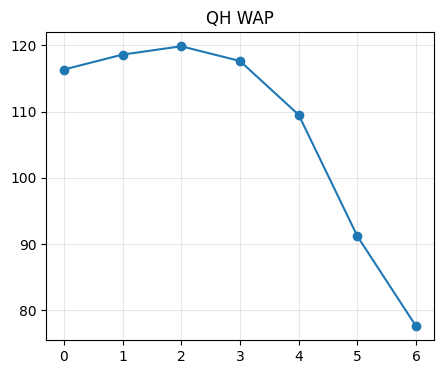

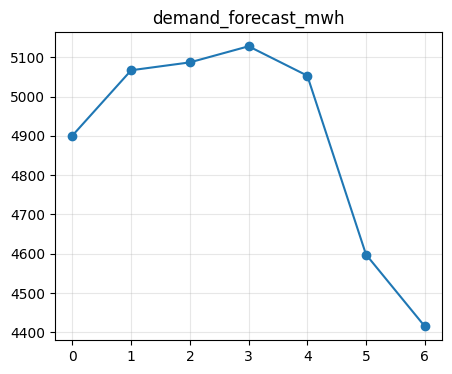

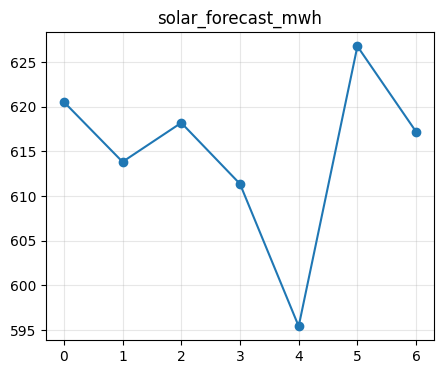

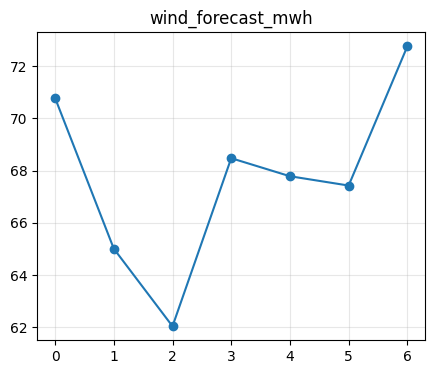

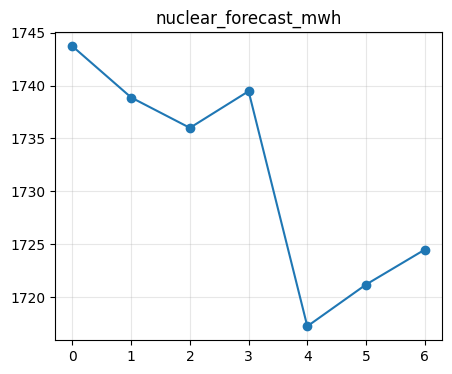

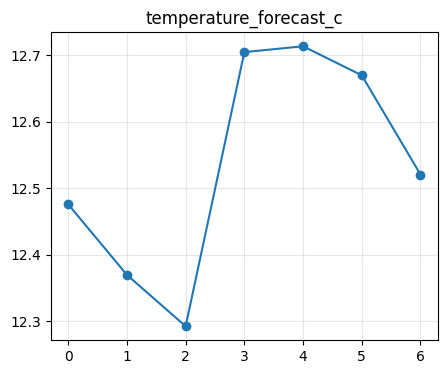

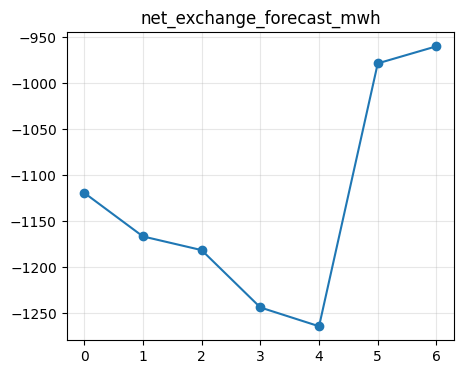

In [23]:
df_clean["weekday"] = df_clean["timestamp"].dt.day_of_week

cols = ["QH WAP", "demand_forecast_mwh", "solar_forecast_mwh", "wind_forecast_mwh",
        "nuclear_forecast_mwh", "temperature_forecast_c", "net_exchange_forecast_mwh"]

for i in cols:
    result = df_clean.groupby("weekday")[i].mean()
    plt.figure(figsize=(5, 4))
    plt.plot(result.index, result.values, marker="o")
    plt.title(i)
    plt.grid(alpha=0.3) 
    plt.show()


График дня каждые 15 мин:

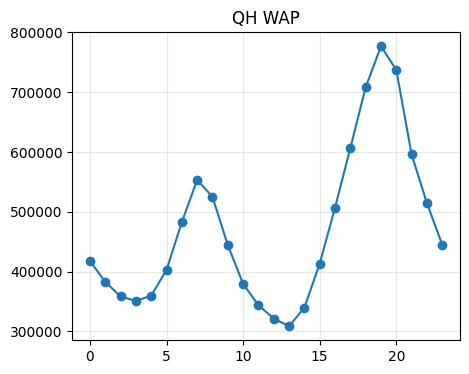

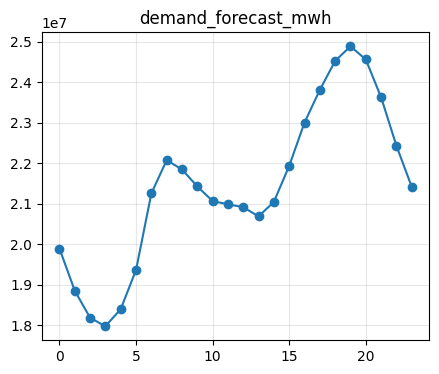

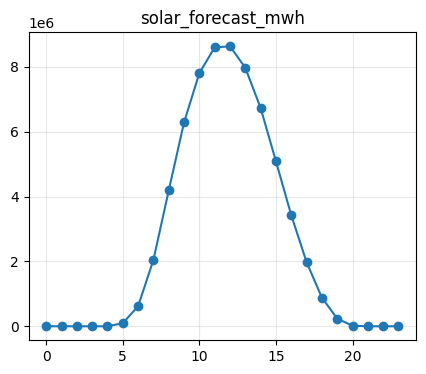

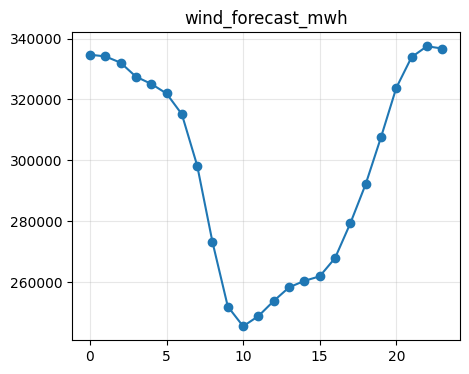

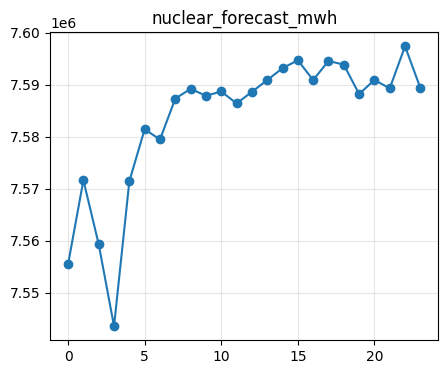

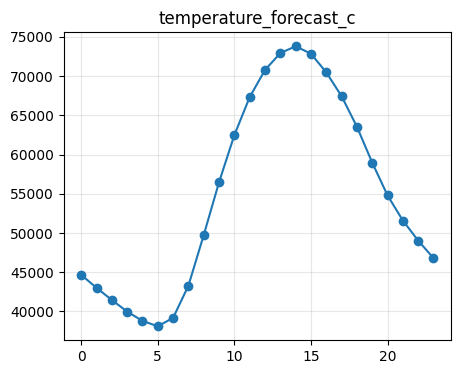

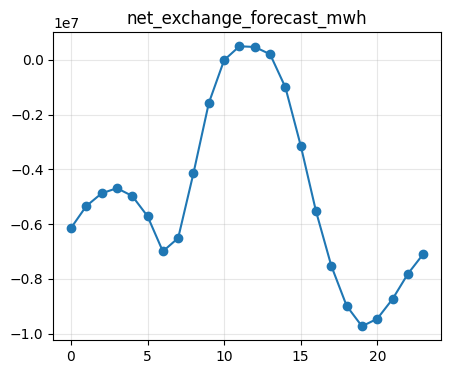

In [24]:
df_clean["days"] = df_clean['timestamp'].dt.hour

for i in cols:
    result = df_clean.groupby('days')[i].sum()
    plt.figure(figsize=(5,4))
    plt.plot(result.index, result.values, marker = "o")

    plt.title(i)
    plt.grid(alpha = 0.3)
    plt.show()

График по месяцам:

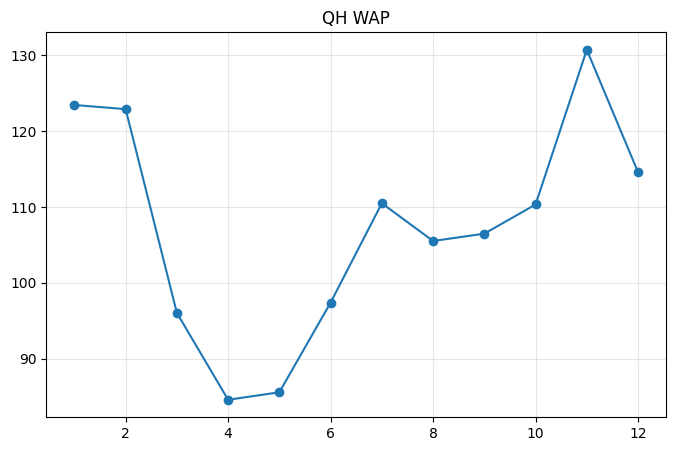

In [25]:
df_clean["month"] = df_clean["timestamp"].dt.month
df_clean["month"]
result = df_clean.groupby('month')["QH WAP"].mean()
plt.figure(figsize=(8,5))
plt.plot(result.index, result.values, marker = "o")

plt.title("QH WAP")
plt.grid(alpha = 0.3)
plt.show()

Расчет по временам года:

In [26]:
seasons = {12: "Зима", 1: "Зима", 2: "Зима",
           3: "Весна", 4: "Весна", 5: "Весна",
           6: "Лето", 7: "Лето", 8: "Лето",
           9: "Осень", 10: "Осень", 11: "Осень"}

df_clean["season"] = df_clean["timestamp"].dt.month.map(seasons)

# среднее, минимум и максимум одной таблицей
print(df_clean.groupby("season")["QH WAP"].agg(["mean", "min", "max"]))

# количество отрицательных, положительных и нулевых цен
QH_min = df_clean[df_clean["QH WAP"] < 0]
QH_pos = df_clean[df_clean["QH WAP"] > 0]
QH_0 = df_clean[df_clean["QH WAP"] == 0]

print(QH_min.groupby("season")["QH WAP"].sum())
print(QH_pos.groupby("season")["QH WAP"].sum())
print(QH_0.groupby("season")["QH WAP"].count())

#прибыль + убыток за сезон
print(df_clean.groupby("season")["QH WAP"].sum())

              mean     min      max
season                             
Весна    88.787579 -561.85  1255.04
Зима    120.229894  -36.25   910.70
Лето    104.551157 -383.94  1149.28
Осень   115.786105 -134.43  1258.87
season
Весна   -56088.53
Зима     -1513.61
Лето    -34913.22
Осень   -11502.47
Name: QH WAP, dtype: float64
season
Весна    2405230.29
Зима     3123162.58
Лето     2803532.40
Осень    3045677.36
Name: QH WAP, dtype: float64
Series([], Name: QH WAP, dtype: int64)
season
Весна    2349141.76
Зима     3121648.97
Лето     2768619.18
Осень    3034174.89
Name: QH WAP, dtype: float64


Можно сделать вывод, что весной меньше всего платят, потому что весной большие убытки, чем в другие времена год, а именно -56088 евро. А Зимой наоборот больше всего прибыли и меньше всего убыли. Скорее всего потому что солнечные батареи не работают 

## Лаги и скользящее среднее

Переберем окна от часа до недели:

In [27]:
windows = [4, 8, 16, 32, 48, 96, 192, 672]   # час, 2, 4, 8, 12, сутки, 2 суток, неделя

results = []

for period in windows:
    rolling_mean = df["QH WAP"].shift(96).rolling(window=period).mean()
    corr = df["QH WAP"].corr(rolling_mean)
    results.append({"period": period, "hours": period / 4, "correlation": corr})

rolling_corr = pd.DataFrame(results)
print(rolling_corr)

best = rolling_corr.loc[rolling_corr["correlation"].idxmax(), "period"]
print("Лучшее окно:", best)

   period  hours  correlation
0       4    1.0     0.611859
1       8    2.0     0.581586
2      16    4.0     0.483058
3      32    8.0     0.315069
4      48   12.0     0.272722
5      96   24.0     0.285414
6     192   48.0     0.262030
7     672  168.0     0.281124
Лучшее окно: 4


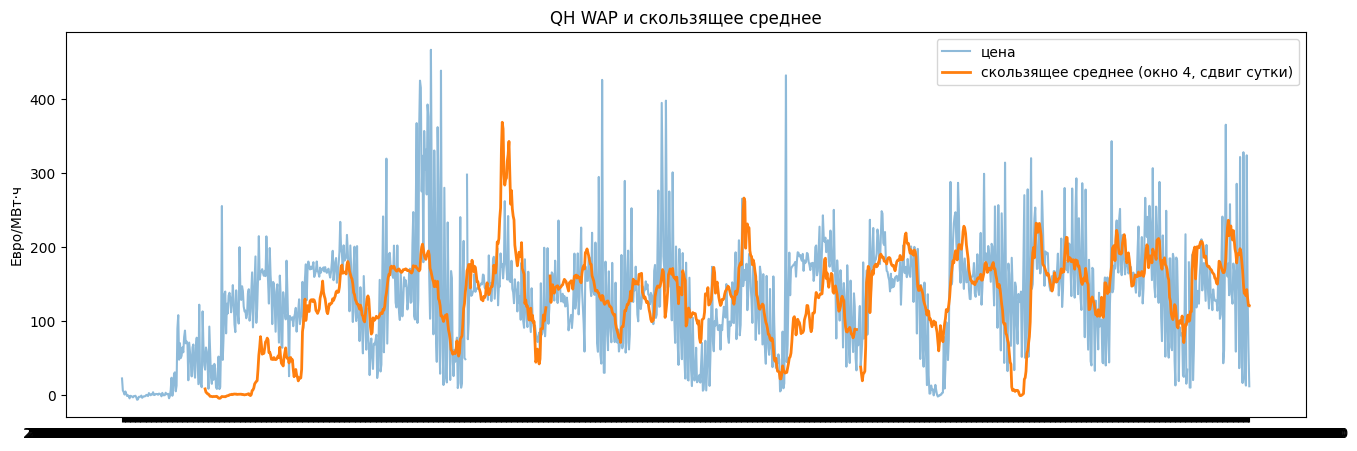

In [28]:
df["roll_mean"] = df["QH WAP"].shift(96).rolling(window=best).mean()

part = df.iloc[:96 * 14]

plt.figure(figsize=(16, 5))
plt.plot(part["timestamp"], part["QH WAP"], alpha=0.5, label="цена")
plt.plot(part["timestamp"], part["roll_mean"], linewidth=2, label=f"скользящее среднее (окно {best}, сдвиг сутки)")
plt.title("QH WAP и скользящее среднее")
plt.ylabel("Евро/МВт·ч")
plt.legend()
plt.show()

Теперь сохраним измененный датасет в новый файл

In [29]:
df_clean = df_clean.drop(columns=["weekday", "days", "month", "season", "lag_1"], errors="ignore")
df_clean.to_csv("df_clean.csv", index=False)

## Вывод

В данных почти нет проблем с качеством. Пропуски есть только в целевой переменной QH WAP (94 штуки), в признаках пропусков нет. Дубликатов не найдено.

Выбросы есть только в QH WAP. Значения за пределами правдоподобного диапазона мы убрали, остальные оставили: резкие скачки цены и отрицательные цены - это реальные ситуации на рынке, а не ошибки. Отрицательная цена значит, что электроэнергии в этот момент слишком много (например, днём при сильном солнце), и производителям выгоднее доплатить, чем снижать выработку.

Остальные признаки выглядят нормально. У solar_forecast_mwh много нулей - это ночь + несолнечные дни, когда солнца нет, поэтому медиана и минимум равны нулю. У nuclear_forecast_mwh значения собираются в несколько уровней - это зависит от того, сколько блоков АЭС работает в данный момент.

По корреляциям:
- сильнее всего цена растёт вместе с потреблением электроэнергии (0.51);
- солнечная генерация и экспорт снижают цену (-0.33 и -0.36);
- ветер и АЭС на цену почти не влияют;
- солнце и экспорт связаны между собой (0.71): когда много солнца, Венгрия больше продаёт соседям.

Корреляция Спирмена почти совпала с Пирсоном, только связь солнца и экспорта стала слабее (0.57). Сильной мультиколлинеарности между признаками нет.

Скользящее среднее со сдвигом на сутки хорошо повторяет общий уровень цены, но с опозданием на день и без резких скачков. Значит, оно подходит как признак, показывающий «какой была цена недавно», но пики модели придётся предсказывать по другим признакам (потребление, солнце, экспорт).